In [2]:
import numpy as np

# Settings
amplitude = 0.10          # Negative values produce a downward bump
nx, ny = 201, 201         # Output grid resolution
n_segments = 2000         # Resolution of the curved boundary

x = np.linspace(0.0, 1.0, nx)
y = np.linspace(0.0, 1.0, ny)
X, Y = np.meshgrid(x, y)

a, b = 1.0 / 3.0, 2.0 / 3.0
y0 = 0.5


def boundary_height(x):
    x = np.asarray(x)
    phase = np.clip((x - a) / (b - a), 0.0, 1.0)
    return y0 + 0.5 * amplitude * (1.0 - np.cos(2.0 * np.pi * phase))


# Approximate the curved portion by line segments.
xb = np.linspace(a, b, n_segments + 1)
yb = boundary_height(xb)

# Exact distances to the two horizontal rays:
# left ray: x <= a; right ray: x >= b.
d2_left = np.maximum(X - a, 0.0)**2 + (Y - y0)**2
d2_right = np.maximum(b - X, 0.0)**2 + (Y - y0)**2
d2 = np.minimum(d2_left, d2_right)

# Distance to each segment of the curved portion.
for i in range(n_segments):
    px, py = xb[i], yb[i]
    vx = xb[i + 1] - px
    vy = yb[i + 1] - py

    # Projection onto the segment, restricted to its endpoints.
    t = ((X - px) * vx + (Y - py) * vy) / (vx*vx + vy*vy)
    t = np.clip(t, 0.0, 1.0)

    segment_d2 = (X - px - t*vx)**2 + (Y - py - t*vy)**2
    d2 = np.minimum(d2, segment_d2)

# Positive above, negative below.
distance = np.sign(Y - boundary_height(X)) * np.sqrt(d2)

# Save three columns: x, y, signed_distance.
# x varies fastest within each constant-y row.
data = np.column_stack((X.ravel(), Y.ravel(), distance.ravel()))

data.astype("<f8").tofile("signed_distance.dat")

print("Saved signed_distance.dat")

Saved signed_distance.dat


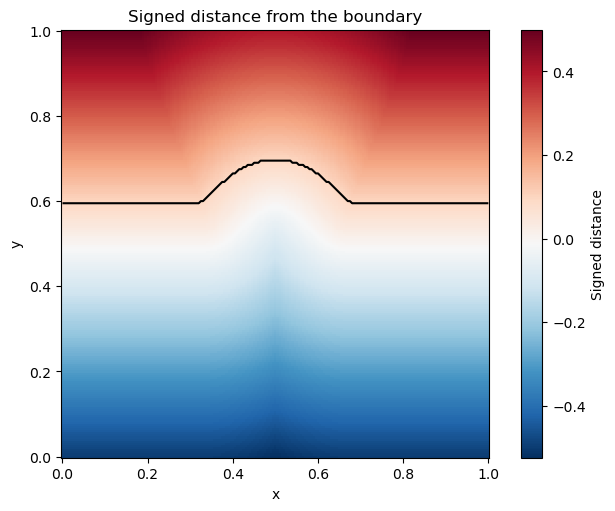

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = np.fromfile("signed_distance.dat", dtype="<f8").reshape(-1, 3)

# Recover the grid; the saved file has x varying fastest.
nx = np.unique(data[:, 0]).size
ny = np.unique(data[:, 1]).size

X = data[:, 0].reshape(ny, nx)
Y = data[:, 1].reshape(ny, nx)
distance = data[:, 2].reshape(ny, nx)

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")

limit = np.max(np.abs(distance))
plot = ax.pcolormesh(X, Y, distance,shading="auto",cmap="RdBu_r",vmin=-limit,vmax=limit)

# The zero contour marks the boundary.
ax.contour(X, Y, profile, levels=[0], colors="black", linewidths=1.5)

fig.colorbar(plot, ax=ax, label="Signed distance")
ax.set(xlabel="x", ylabel="y", title="Signed distance from the boundary")
ax.set_aspect("equal")
plt.show()

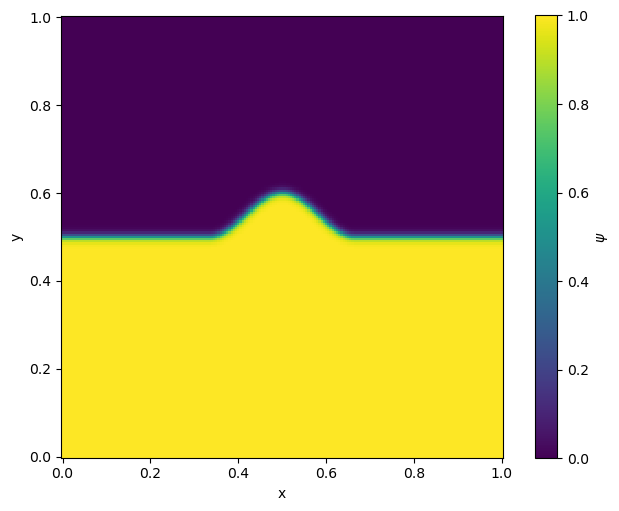

In [9]:
w = 0.02  # Width between psi = 0.9 and psi = 0.1
psi = 0.5 * (1.0 - np.tanh(2.0 * np.log(3.0) * distance / w))

# Plot
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
plot = ax.pcolormesh(X, Y, psi, shading="auto", cmap="viridis",
                     vmin=0, vmax=1)
fig.colorbar(plot, ax=ax, label=r"$\psi$")
ax.set(xlabel="x", ylabel="y")
ax.set_aspect("equal")
plt.show()

# Save binary columns: x, y, psi
output = np.column_stack((X.ravel(), Y.ravel(), psi.ravel()))
output.astype("<f8").tofile("phase_field.dat")